# DR Grading — Swin Transformer V2 Small (EEEM068)
**Run all cells top to bottom. Edit only the Config cell.**

Key choices:
- SwinV2-Small (50M params, 256px) — post-norm + scaled cosine attention, more stable than V1
- Offline weight loading for Surrey HPC (no internet on compute nodes)
- Augmentation ablation V1→V4, three imbalance strategies, TTA at inference

In [22]:
# ── Install dependencies (run once per session) ───────────────────────────────
import subprocess, sys

def _ensure(pkg, import_name=None):
    name = import_name or pkg.split(">=")[0].replace("-","_")
    try:
        __import__(name)
    except ImportError:
        print(f"Installing {pkg}...")
        subprocess.check_call([sys.executable,"-m","pip","install","-q",pkg])
        print(f"  done.")

_ensure("timm>=0.9.0", "timm")
_ensure("huggingface_hub", "huggingface_hub")
print("Dependencies ready.")

Dependencies ready.


In [23]:
# ── Imports ───────────────────────────────────────────────────────────────────
from __future__ import annotations
import gc, json, os, random
from contextlib import nullcontext
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import (
    classification_report, cohen_kappa_score, confusion_matrix,
    f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from skimage.filters import frangi
from skimage.restoration import denoise_bilateral
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms
from tqdm.auto import tqdm
import torchvision.models as tv_models

import timm
print(f"timm {timm.__version__}")

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

timm 1.0.26


In [24]:
# ── CONFIG — edit only this cell ──────────────────────────────────────────────
EXPERIMENT_NAME  = "swinv2_run_A_extended"          # changed — new experiment name
DATA_ROOT        = "/scratch/AML_G14_CW/Data/diabetic-retinopathy-detection/train"
LABELS_CSV       = "/scratch/AML_G14_CW/Data/diabetic-retinopathy-detection/trainLabels.csv"
IMAGE_EXTENSION  = ".jpeg"
SEED             = 42
TRAIN_VAL_SPLIT  = 0.2
NUM_WORKERS      = 4
DEVICE           = "auto"
IMAGE_SIZE       = 256   # SwinV2-Small native resolution — do not change
NUM_CLASSES      = 5
# Augmentation version — change per ablation run
# "v1_none" | "v2_basic" | "v3_full" | "v4_mixup"
AUGMENT_VERSION  = "v3_full"
HFLIP_PROB       = 0.5
VFLIP_PROB       = 0.5
ROTATION_DEG     = 30
COLOR_JITTER     = dict(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05)
RANDOM_ERASE_PROB= 0.2
MIXUP_ALPHA      = 0.4
USE_PREPROCESSING= True
PREPROCESS       = dict(
    crop_black=True, circular_mask=True, glare_inpaint=False,
    ben_graham=True, clahe=True, green_enhance=False,
    vessel_frangi=False, red_enhance=False, adaptive_denoise=False,
)
# ── Model ─────────────────────────────────────────────────────────────────────
ARCHITECTURE     = "swinv2_small_window8_256"
PRETRAINED       = True
DROPOUT          = 0.3
FREEZE_BACKBONE_EPOCHS = 5              # changed — was 3, longer warmup reduces instability
# Offline weights (Surrey HPC has no internet on compute nodes)
# Download on login node then set path:
#   mkdir -p /scratch/mesa_caches/AML/AML_G14_CW/weights/
#   wget -O /scratch/mesa_caches/AML/AML_G14_CW/weights/swinv2_small.safetensors \
#     https://huggingface.co/timm/swinv2_small_window8_256.ms_in1k/resolve/main/model.safetensors
WEIGHTS_PATH     = "/scratch/mesa_caches/AML/AML_G14_CW/weights/swinv2_small.safetensors"
# Set to None if you have internet access
# ── Training ──────────────────────────────────────────────────────────────────
# VRAM guide: 8GB→batch=4, 16GB→batch=16, 40GB(A100)→batch=32
BATCH_SIZE       = 16
EPOCHS           = 40                   # changed — was 25, more room to converge
LR               = 5e-5                 # changed — was 1e-4, lower LR reduces val kappa oscillation
WEIGHT_DECAY     = 3e-2                 # changed — was 1e-2, higher regularisation fights overfitting
OPTIMIZER        = "adamw"
SCHEDULER        = "cosine"
EARLY_STOPPING_PATIENCE = 10            # changed — was 6, was stopping too early at ep 18
MIXED_PRECISION  = True
GRADIENT_CLIP_NORM = 1.0
LABEL_SMOOTHING  = 0.1
# ── Imbalance strategy (pick ONE) ─────────────────────────────────────────────
# A: CLASS_WEIGHTS_AUTO=True,  WEIGHTED_SAMPLING=False, USE_FOCAL_LOSS=False
# B: CLASS_WEIGHTS_AUTO=False, WEIGHTED_SAMPLING=True,  USE_FOCAL_LOSS=False  ← active
# C: CLASS_WEIGHTS_AUTO=True,  WEIGHTED_SAMPLING=False, USE_FOCAL_LOSS=True
CLASS_WEIGHTS_AUTO = False
WEIGHTED_SAMPLING  = True
USE_FOCAL_LOSS     = False
FOCAL_GAMMA        = 2.0
# ── TTA ───────────────────────────────────────────────────────────────────────
USE_TTA = True
TTA_N   = 5

In [25]:
# ── Helpers ───────────────────────────────────────────────────────────────────
def get_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for p in [cwd, cwd.parent]:
        if (p/"data").is_dir() or (p/"notebooks").is_dir():
            return p
    return cwd

REPO_ROOT = get_repo_root()
os.chdir(REPO_ROOT)
print("Repo root:", REPO_ROOT)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def resolve_device(spec):
    s = (spec or "auto").lower()
    if s == "auto":
        if torch.cuda.is_available(): return torch.device("cuda")
        if getattr(torch.backends,"mps",None) and torch.backends.mps.is_available():
            return torch.device("mps")
        return torch.device("cpu")
    return torch.device(s)

def gpu_status(label=""):
    if not torch.cuda.is_available():
        print("No CUDA GPU — running on CPU"); return
    alloc = torch.cuda.memory_allocated()/1e9
    res   = torch.cuda.memory_reserved()/1e9
    total = torch.cuda.get_device_properties(0).total_memory/1e9
    print(f"[{label}] {torch.cuda.get_device_name(0)} | "
          f"total {total:.1f}GB | allocated {alloc:.2f}GB | free {total-res:.2f}GB")
    if res > total*0.8:
        print("  WARNING: >80% VRAM used — restart kernel if you get OOM")

def clear_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    print("GPU cache cleared.")

set_seed(SEED)
device = resolve_device(DEVICE)
print("Device:", device)
gpu_status("startup")

Repo root: /scratch/AML_G14_CW
Device: cuda
[startup] NVIDIA RTX A4000 | total 16.7GB | allocated 3.48GB | free 12.64GB


In [26]:
# ── Dataset + preprocessing + transforms ──────────────────────────────────────
def preprocess_fundus_pil(image: Image.Image, steps: dict) -> Image.Image:
    img     = np.array(image)
    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)
    img_bgr = cv2.resize(img_bgr, (300, 300), interpolation=cv2.INTER_AREA)  # resize FIRST: ~100x faster
    if steps.get("crop_black", True):
        gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
        _, thresh = cv2.threshold(gray, 10, 255, cv2.THRESH_BINARY)
        coords = cv2.findNonZero(thresh)
        if coords is not None:
            x, y, w, h = cv2.boundingRect(coords)
            img_bgr = img_bgr[y:y+h, x:x+w]
    if steps.get("circular_mask", True):
        h, w = img_bgr.shape[:2]
        mask = np.zeros((h,w), dtype=np.uint8)
        cv2.circle(mask, (w//2,h//2), int(0.48*min(h,w)), 255, -1)
        img_bgr = cv2.bitwise_and(img_bgr, img_bgr, mask=mask)
    if steps.get("ben_graham", True):
        blur = cv2.GaussianBlur(img_bgr, (0,0), sigmaX=10)
        img_bgr = cv2.addWeighted(img_bgr, 4, blur, -4, 128)
    if steps.get("clahe", True):
        lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        img_bgr = cv2.cvtColor(cv2.merge((clahe.apply(l),a,b)), cv2.COLOR_LAB2BGR)
    if steps.get("vessel_frangi", False):
        green = cv2.split(img_bgr)[1].astype(np.float32)/255.0
        v = frangi(green)
        v = (255*v/(v.max()+1e-6)).astype(np.uint8)
        img_bgr = cv2.addWeighted(img_bgr,0.8,cv2.cvtColor(v,cv2.COLOR_GRAY2BGR),0.2,0)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    if steps.get("adaptive_denoise", False):
        dn = denoise_bilateral(img_rgb, sigma_color=0.05, sigma_spatial=3, channel_axis=-1)
        img_rgb = (np.clip(dn,0,1)*255).astype(np.uint8)
    return Image.fromarray(img_rgb)


class RetinaDataset(Dataset):
    def __init__(self, frame, data_root, image_extension, transform, preprocess):
        self.frame = frame.reset_index(drop=True)
        self.data_root = Path(data_root)
        ext = image_extension if str(image_extension).startswith(".") else f".{image_extension}"
        self.image_extension = ext
        self.transform = transform
        self.preprocess = bool(preprocess)
        self.cache_dir = self.data_root.parent / "preprocessed_cache"
        if self.preprocess: self.cache_dir.mkdir(parents=True, exist_ok=True)

    def __len__(self): return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        stem = str(row["image"])
        if not stem.lower().endswith((".jpeg",".jpg",".png")):
            stem = stem + self.image_extension
        from PIL import ImageFile; ImageFile.LOAD_TRUNCATED_IMAGES = True
        _stem = Path(stem).stem if stem.lower().endswith((".jpeg",".jpg",".png")) else stem
        if self.preprocess:
            _cp = self.cache_dir / f"{_stem}.png"
            if _cp.exists() and _cp.stat().st_size > 1000:
                image = Image.open(_cp).convert("RGB")  # valid cache hit
            else:
                if _cp.exists(): _cp.unlink()  # remove corrupt/empty file
                image = Image.open(self.data_root/stem).convert("RGB")
                image = preprocess_fundus_pil(image, PREPROCESS)
                try: image.save(_cp, format="PNG", optimize=False)
                except OSError: pass  # disk full — skip save, still trains
        else:
            image = Image.open(self.data_root/stem).convert("RGB")
        label = int(row["level"])
        if self.transform is not None:
            image = self.transform(image)
        return image, label


def build_transforms(train: bool, version: str = "v3_full") -> transforms.Compose:
    size = int(IMAGE_SIZE)
    if not train:
        return transforms.Compose([
            transforms.Resize(int(size*1.05)),
            transforms.CenterCrop(size),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ])
    v = version.lower()
    if v == "v1_none":
        ops = [transforms.Resize(int(size*1.05)), transforms.CenterCrop(size)]
    elif v == "v2_basic":
        ops = [
            transforms.Resize(int(size*1.12)), transforms.RandomCrop(size),
            transforms.RandomHorizontalFlip(p=float(HFLIP_PROB)),
            transforms.RandomVerticalFlip(p=float(VFLIP_PROB)),
            transforms.RandomRotation(degrees=float(ROTATION_DEG)),
        ]
    elif v in ("v3_full","v4_mixup"):
        ops = [
            transforms.Resize(int(size*1.15)), transforms.RandomCrop(size),
            transforms.RandomHorizontalFlip(p=float(HFLIP_PROB)),
            transforms.RandomVerticalFlip(p=float(VFLIP_PROB)),
            transforms.RandomRotation(degrees=float(ROTATION_DEG)),
            transforms.ColorJitter(**{k:float(v2) for k,v2 in COLOR_JITTER.items()}),
        ]
    else:
        raise ValueError(f"Unknown AUGMENT_VERSION: {version}")
    ops.append(transforms.ToTensor())
    if v in ("v3_full","v4_mixup") and float(RANDOM_ERASE_PROB)>0:
        ops.append(transforms.RandomErasing(p=float(RANDOM_ERASE_PROB)))
    ops.append(transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD))
    return transforms.Compose(ops)


def mixup_batch(images, labels, alpha=0.4):
    lam = np.random.beta(alpha, alpha) if alpha > 0 else 1.0
    idx = torch.randperm(images.size(0), device=images.device)
    return lam*images+(1-lam)*images[idx], labels, labels[idx], lam

print("Dataset utilities loaded.")

Dataset utilities loaded.


In [27]:
# ── Load CSV + stratified split ───────────────────────────────────────────────
def _resolve(p):
    p = str(p)
    if p.startswith("/"): return Path(p)
    if p.startswith("./"): return Path(p).resolve()
    return (REPO_ROOT / p).resolve()

labels_path = _resolve(LABELS_CSV)
data_root   = _resolve(DATA_ROOT)
print(f"Labels : {labels_path}  exists={labels_path.exists()}")
print(f"Images : {data_root}  exists={data_root.exists()}")
assert labels_path.exists(), f"CSV not found: {labels_path}"
assert data_root.exists(),   f"Image dir not found: {data_root}"

full_df = pd.read_csv(labels_path)
full_df.columns = [c.strip().lower() for c in full_df.columns]
assert "image" in full_df.columns and "level" in full_df.columns, (
    f"Need columns 'image','level'. Got: {full_df.columns.tolist()}")

train_df, val_df = train_test_split(
    full_df, test_size=float(TRAIN_VAL_SPLIT),
    stratify=full_df["level"], random_state=int(SEED))
print(f"Train: {len(train_df)}  Val: {len(val_df)}")
print("Class dist (train):", train_df["level"].value_counts().sort_index().to_dict())

Labels : /scratch/AML_G14_CW/Data/diabetic-retinopathy-detection/trainLabels.csv  exists=True
Images : /scratch/AML_G14_CW/Data/diabetic-retinopathy-detection/train  exists=True
Train: 28100  Val: 7026
Class dist (train): {0: 20648, 1: 1954, 2: 4234, 3: 698, 4: 566}


In [28]:
# Cache warm-up: runs ONCE (~4-5 min), forever skipped after.
if USE_PREPROCESSING:
    from PIL import ImageFile; ImageFile.LOAD_TRUNCATED_IMAGES=True
    _cd=data_root.parent/"preprocessed_cache"; _cd.mkdir(parents=True,exist_ok=True)
    _stems=[Path(str(r["image"])).stem if str(r["image"]).lower().endswith((".jpeg",".jpg",".png"))
            else str(r["image"]) for _,r in full_df.iterrows()]
    _done=sum(1 for s in _stems if (_cd/f"{s}.png").exists())
    # Validate cache: remove empty/corrupt files from previous failed runs
    _corrupt = [f for f in _cd.glob('*.png') if f.stat().st_size < 1000]
    if _corrupt:
        print(f'Removing {len(_corrupt)} corrupt/empty cache files...')
        for f in _corrupt: f.unlink()
        _done = sum(1 for s in _stems if (_cd/f'{s}.png').exists())
    if _done==len(_stems): print(f"Cache ready ({_done} imgs). Skipping.")
    else:
        print(f"Building cache: {_done}/{len(_stems)}. ~4-5 min.")
        _sk=0
        for _s in tqdm(_stems,desc="Caching",unit="img"):
            _p=_cd/f"{_s}.png"
            if _p.exists(): continue
            try:
                _i=Image.open(data_root/f"{_s}{IMAGE_EXTENSION}").convert("RGB")
                _i=preprocess_fundus_pil(_i,PREPROCESS)
                _i.save(_p,format="PNG",optimize=False)
            except Exception as _e: _sk+=1; print(f"  Skip {_s}: {_e}")
        print(f"Done: {len(_stems)-_sk} cached, {_sk} skipped.")

# ── DataLoaders ───────────────────────────────────────────────────────────────
train_tf = build_transforms(train=True,  version=AUGMENT_VERSION)
val_tf   = build_transforms(train=False, version=AUGMENT_VERSION)
train_ds = RetinaDataset(train_df, data_root, IMAGE_EXTENSION, train_tf, USE_PREPROCESSING)
val_ds   = RetinaDataset(val_df,   data_root, IMAGE_EXTENSION, val_tf,   USE_PREPROCESSING)

train_sampler = None
if WEIGHTED_SAMPLING:
    counts = train_df["level"].value_counts().to_dict()
    sw = train_df["level"].map(lambda y: 1.0/counts[int(y)]).to_numpy(dtype=np.float64)
    train_sampler = WeightedRandomSampler(
        torch.as_tensor(sw, dtype=torch.double), len(sw), replacement=True)
    print("Imbalance: WeightedRandomSampler")
elif CLASS_WEIGHTS_AUTO:
    print("Imbalance: class-weighted loss")
if USE_FOCAL_LOSS:
    print("Loss: Focal Loss")

train_loader = DataLoader(train_ds, batch_size=int(BATCH_SIZE),
    shuffle=(train_sampler is None), sampler=train_sampler,
    num_workers=int(NUM_WORKERS), pin_memory=torch.cuda.is_available(), drop_last=True)
val_loader = DataLoader(val_ds, batch_size=int(BATCH_SIZE),
    shuffle=False, num_workers=int(NUM_WORKERS), pin_memory=torch.cuda.is_available())
print(f"Train batches: {len(train_loader)}  Val batches: {len(val_loader)}")

Removing 338 corrupt/empty cache files...
Building cache: 33169/35126. ~4-5 min.


Caching: 100%|██████████| 35126/35126 [01:45<00:00, 331.65img/s]  

Done: 35126 cached, 0 skipped.
Imbalance: WeightedRandomSampler
Train batches: 1756  Val batches: 440


In [29]:
# ── Model — SwinV2-Small ──────────────────────────────────────────────────────
def _is_swin(arch): return arch.lower().startswith("swin")


def _load_swin_weights(backbone, weights_path):
    """Load local .safetensors with strict=False — skips ImageNet head + attn_mask."""
    from timm.models._helpers import load_checkpoint
    result = load_checkpoint(backbone, weights_path, strict=False)
    head_missing  = [k for k in result.missing_keys   if "head" in k]
    other_missing = [k for k in result.missing_keys   if "head" not in k]
    ignored       = [k for k in result.unexpected_keys if "head.fc" in k or "attn_mask" in k]
    other_extra   = [k for k in result.unexpected_keys if k not in ignored]
    print(f"  Head keys (randomly init, expected): {len(head_missing)}")
    print(f"  Ignored ImageNet head + attn masks : {len(ignored)}")
    if other_missing: print(f"  WARNING unexpected missing: {other_missing}")
    if other_extra:   print(f"  WARNING unexpected extra:   {other_extra}")


def build_model():
    if _is_swin(ARCHITECTURE):
        # Step 1: build blank architecture
        backbone = timm.create_model(
            ARCHITECTURE, pretrained=False, num_classes=0, global_pool="avg")
        feat_dim = backbone.num_features  # 768 for SwinV2-Small

        # Step 2: attach custom head BEFORE loading weights
        backbone.custom_head = nn.Sequential(
            nn.LayerNorm(feat_dim),
            nn.Dropout(p=float(DROPOUT)),
            nn.Linear(feat_dim, int(NUM_CLASSES)),
        )
        _base_forward = backbone.forward
        backbone.forward = lambda x: backbone.custom_head(_base_forward(x))

        # Step 3: load weights — local file → HuggingFace → random init
        _wpath = globals().get("WEIGHTS_PATH", None)
        _local = _wpath is not None and Path(str(_wpath)).exists()

        if _local:
            print(f"Loading weights from local file: {_wpath}")
            _load_swin_weights(backbone, str(_wpath))
            print("Local pretrained weights loaded.")
        elif bool(PRETRAINED):
            try:
                print("Downloading from HuggingFace...")
                tmp = timm.create_model(ARCHITECTURE, pretrained=True, num_classes=0, global_pool="avg")
                own_sd = backbone.state_dict()
                src_sd = {k:v for k,v in tmp.state_dict().items() if k in own_sd and "head" not in k}
                own_sd.update(src_sd); backbone.load_state_dict(own_sd, strict=False); del tmp
                print("Downloaded weights loaded.")
            except Exception as e:
                print(f"Download failed: {e}")
                print("Set WEIGHTS_PATH in config (see download instructions above) or PRETRAINED=False")
                raise
        else:
            print("PRETRAINED=False — random init (scratch experiment).")

        total = sum(p.numel() for p in backbone.parameters())/1e6
        print(f"SwinV2-Small | {total:.1f}M params | feat_dim={feat_dim}")
        return backbone

    else:
        # EfficientNet / ViT fallback for teammates
        m = getattr(tv_models, ARCHITECTURE)(weights="DEFAULT" if PRETRAINED else None)
        a = ARCHITECTURE.lower()
        if a.startswith("efficientnet"):
            in_f = m.classifier[1].in_features
            m.classifier = nn.Sequential(nn.Dropout(DROPOUT,inplace=True), nn.Linear(in_f,NUM_CLASSES))
        elif a.startswith("vit"):
            in_f = m.heads.head.in_features
            m.heads.head = nn.Linear(in_f, NUM_CLASSES)
        return m


def set_backbone_trainable(model, architecture, train_backbone):
    if _is_swin(architecture):
        for n, p in model.named_parameters():
            p.requires_grad = True if "custom_head" in n else bool(train_backbone)
    else:
        for p in model.parameters(): p.requires_grad = True


# Clear GPU before loading
clear_gpu()
gpu_status("before model load")
model = build_model().to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)/1e6
print(f"Trainable params (before freeze): {trainable:.1f}M")
gpu_status("after model load")

GPU cache cleared.
[before model load] NVIDIA RTX A4000 | total 16.7GB | allocated 3.47GB | free 13.12GB
Downloaded weights loaded.
SwinV2-Small | 49.0M params | feat_dim=768
Trainable params (before freeze): 49.0M
[after model load] NVIDIA RTX A4000 | total 16.7GB | allocated 3.67GB | free 12.97GB


In [30]:
# ── Loss + Optimiser + Scheduler ──────────────────────────────────────────────
def compute_class_weights(y, num_classes):
    counts = np.bincount(y, minlength=num_classes).astype(np.float64)
    counts[counts==0] = 1.0
    return torch.tensor((len(y)/(num_classes*counts)).astype(np.float32), device=device)


class FocalLoss(nn.Module):
    """Focal Loss — down-weights easy examples, focuses on hard minority classes."""
    def __init__(self, gamma=2.0, alpha=None, weight=None):
        super().__init__()
        self.gamma = float(gamma)
        self.alpha = None if alpha is None else float(alpha)
        self.weight = weight
    def forward(self, logits, target):
        ce   = F.cross_entropy(logits, target, weight=self.weight, reduction="none")
        pt   = torch.exp(-ce)
        loss = ((1-pt)**self.gamma)*ce
        if self.alpha is not None: loss = self.alpha*loss
        return loss.mean()


set_backbone_trainable(model, ARCHITECTURE, train_backbone=(int(FREEZE_BACKBONE_EPOCHS)==0))

class_weights = compute_class_weights(train_df["level"].to_numpy(), NUM_CLASSES) if CLASS_WEIGHTS_AUTO else None
if CLASS_WEIGHTS_AUTO: print("Class weights:", class_weights.cpu().numpy().round(3))

if USE_FOCAL_LOSS:
    criterion = FocalLoss(gamma=float(FOCAL_GAMMA), weight=class_weights)
    print(f"Loss: FocalLoss (gamma={FOCAL_GAMMA})")
else:
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=float(LABEL_SMOOTHING))
    print(f"Loss: CrossEntropyLoss (label_smoothing={LABEL_SMOOTHING})")

# Layer-wise LR: backbone 10x lower than head (prevents catastrophic forgetting)
if _is_swin(ARCHITECTURE):
    param_groups = [
        {"params":[p for n,p in model.named_parameters() if "custom_head" not in n and p.requires_grad], "lr":float(LR)*0.1},
        {"params":[p for n,p in model.named_parameters() if "custom_head"     in n and p.requires_grad], "lr":float(LR)},
    ]
else:
    param_groups = [p for p in model.parameters() if p.requires_grad]

optimizer = torch.optim.AdamW(param_groups, lr=float(LR), weight_decay=float(WEIGHT_DECAY))
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=int(EPOCHS), eta_min=1e-7)
print(f"Optimiser: AdamW | Scheduler: cosine | LR: {LR}")

Loss: CrossEntropyLoss (label_smoothing=0.1)
Optimiser: AdamW | Scheduler: cosine | LR: 5e-05


In [31]:
# ── Training loop ─────────────────────────────────────────────────────────────
use_amp   = bool(MIXED_PRECISION) and device.type == "cuda"
scaler    = torch.amp.GradScaler("cuda") if use_amp else None
use_mixup = AUGMENT_VERSION.lower() == "v4_mixup"


def run_epoch(loader, train_mode: bool):
    model.train(train_mode)
    total_loss, total_n = 0.0, 0
    preds_list, labels_list = [], []

    for images, labels in tqdm(loader, leave=False, desc="train" if train_mode else "val"):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        if train_mode:
            optimizer.zero_grad(set_to_none=True)

        mixed_b, lam = None, 1.0
        if train_mode and use_mixup:
            images, labels, mixed_b, lam = mixup_batch(images, labels, float(MIXUP_ALPHA))

        ctx = torch.autocast(device_type="cuda", enabled=True) if use_amp else nullcontext()
        with ctx:
            logits = model(images)
            loss = (lam*criterion(logits,labels)+(1-lam)*criterion(logits,mixed_b)
                    if (train_mode and use_mixup and mixed_b is not None)
                    else criterion(logits, labels))

        if train_mode:
            if use_amp and scaler:
                scaler.scale(loss).backward()
                if GRADIENT_CLIP_NORM:
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_(model.parameters(), float(GRADIENT_CLIP_NORM))
                scaler.step(optimizer); scaler.update()
            else:
                loss.backward()
                if GRADIENT_CLIP_NORM:
                    nn.utils.clip_grad_norm_(model.parameters(), float(GRADIENT_CLIP_NORM))
                optimizer.step()

        total_loss += float(loss.item())*labels.size(0)
        total_n    += labels.size(0)
        preds_list.append(logits.argmax(1).detach().cpu())
        labels_list.append(labels.detach().cpu())

    y_pred = torch.cat(preds_list).numpy()
    y_true = torch.cat(labels_list).numpy()
    return total_loss/max(total_n,1), cohen_kappa_score(y_true,y_pred,weights="quadratic"), y_true, y_pred


ckpt_dir = (REPO_ROOT/"checkpoints").resolve(); ckpt_dir.mkdir(parents=True, exist_ok=True)
out_dir  = (REPO_ROOT/"outputs").resolve();     out_dir.mkdir(parents=True, exist_ok=True)
best_path = ckpt_dir/f"{EXPERIMENT_NAME}_best.pt"
log_path  = ckpt_dir/f"{EXPERIMENT_NAME}_log.json"

freeze_epochs = int(FREEZE_BACKBONE_EPOCHS)
best_kappa    = -1.0
patience_left = int(EARLY_STOPPING_PATIENCE)
history       = {"train_loss":[],"val_loss":[],"val_kappa":[],"epoch":[]}

print(f"\nTraining: {EXPERIMENT_NAME}")
print(f"Augment: {AUGMENT_VERSION} | Epochs: {EPOCHS} | Batch: {BATCH_SIZE} | AMP: {use_amp}")
print(f"Backbone frozen for first {freeze_epochs} epoch(s)")
print("-"*70)

for epoch in range(int(EPOCHS)):
    train_backbone = (epoch >= freeze_epochs)
    set_backbone_trainable(model, ARCHITECTURE, train_backbone)

    if train_backbone and epoch == freeze_epochs and freeze_epochs > 0:
        if _is_swin(ARCHITECTURE):
            pg = [
                {"params":[p for n,p in model.named_parameters() if "custom_head" not in n and p.requires_grad],"lr":float(LR)*0.1},
                {"params":[p for n,p in model.named_parameters() if "custom_head"     in n and p.requires_grad],"lr":float(LR)},
            ]
        else:
            pg = [p for p in model.parameters() if p.requires_grad]
        optimizer = torch.optim.AdamW(pg, lr=float(LR), weight_decay=float(WEIGHT_DECAY))
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=max(1, int(EPOCHS)-epoch), eta_min=1e-7)
        print(f"  [Epoch {epoch+1}] Backbone unfrozen — full fine-tune")

    tl, tk, _, _ = run_epoch(train_loader, True)
    vl, vk, _, _ = run_epoch(val_loader,   False)
    scheduler.step()
    cur_lr = optimizer.param_groups[-1]["lr"]

    history["train_loss"].append(round(tl,5))
    history["val_loss"].append(round(vl,5))
    history["val_kappa"].append(round(vk,5))
    history["epoch"].append(epoch+1)

    improved = vk > best_kappa and not np.isnan(vk)
    print(f"Ep {epoch+1:3d}/{EPOCHS} {'★' if improved else ' '}| "
          f"train {tl:.4f} κ={tk:.4f} | val {vl:.4f} κ={vk:.4f} | lr {cur_lr:.2e}")

    if improved:
        best_kappa = vk; patience_left = int(EARLY_STOPPING_PATIENCE)
        torch.save({"model_state":model.state_dict(),"epoch":epoch,"val_kappa":vk,
                    "config":{"EXPERIMENT_NAME":EXPERIMENT_NAME,"ARCHITECTURE":ARCHITECTURE,
                               "AUGMENT_VERSION":AUGMENT_VERSION,"IMAGE_SIZE":IMAGE_SIZE}}, best_path)
        print(f"  Saved best (κ={vk:.4f}) → {best_path}")
    else:
        patience_left -= 1
        if patience_left <= 0: print("Early stopping."); break

with open(log_path,"w") as f: json.dump(history,f,indent=2)
print(f"\nDone. Best val κ = {best_kappa:.4f}  |  Log → {log_path}")


Training: swinv2_run_A_extended
Augment: v3_full | Epochs: 40 | Batch: 16 | AMP: True
Backbone frozen for first 5 epoch(s)
----------------------------------------------------------------------


Ep   1/40 ★| train 1.5631 κ=0.3219 | val 1.4383 κ=0.2489 | lr 4.99e-05
  Saved best (κ=0.2489) → /scratch/AML_G14_CW/checkpoints/swinv2_run_A_extended_best.pt


Ep   2/40  | train 1.4638 κ=0.4908 | val 1.4781 κ=0.2330 | lr 4.97e-05


Ep   3/40 ★| train 1.4348 κ=0.5121 | val 1.3135 κ=0.3376 | lr 4.93e-05
  Saved best (κ=0.3376) → /scratch/AML_G14_CW/checkpoints/swinv2_run_A_extended_best.pt


Ep   4/40 ★| train 1.4171 κ=0.5295 | val 1.3207 κ=0.3412 | lr 4.88e-05
  Saved best (κ=0.3412) → /scratch/AML_G14_CW/checkpoints/swinv2_run_A_extended_best.pt


...

Ep  33/40  | train 0.8072 κ=0.8876 | val 1.1202 κ=0.6124 | lr 4.87e-06


Ep  34/40  | train 0.8052 κ=0.8915 | val 1.0127 κ=0.6521 | lr 3.63e-06


Ep  35/40  | train 0.7994 κ=0.8911 | val 1.0991 κ=0.6146 | lr 2.57e-06


Ep  36/40  | train 0.7977 κ=0.8938 | val 1.0393 κ=0.6359 | lr 1.69e-06


Ep  37/40  | train 0.8006 κ=0.8928 | val 1.0839 κ=0.6185 | lr 9.99e-07
Early stopping.

Done. Best val κ = 0.6654  |  Log → /scratch/AML_G14_CW/checkpoints/swinv2_run_A_extended_log.json


In [32]:
# ── Evaluation — standard + TTA ───────────────────────────────────────────────
ckpt = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state"])
model.eval()
print(f"Loaded best checkpoint (epoch {ckpt['epoch']+1}, κ={ckpt['val_kappa']:.4f})")

_, std_kappa, y_true, y_pred = run_epoch(val_loader, False)
grades = ["0-No DR","1-Mild","2-Moderate","3-Severe","4-Proliferative"]

print("\n" + "="*60)
print(f"  Standard evaluation — {EXPERIMENT_NAME}")
print("="*60)
print(f"  Quadratic Kappa  : {std_kappa:.4f}")
print(f"  Macro F1         : {f1_score(y_true,y_pred,average='macro',zero_division=0):.4f}")
print(f"  Macro Precision  : {precision_score(y_true,y_pred,average='macro',zero_division=0):.4f}")
print(f"  Macro Recall     : {recall_score(y_true,y_pred,average='macro',zero_division=0):.4f}")
print("\n  Per-class F1:")
for g, f in zip(grades, f1_score(y_true,y_pred,average=None,zero_division=0)):
    print(f"    {g:22s}: {f:.4f}  {'█'*int(f*20)}")
print()
print(classification_report(y_true, y_pred, target_names=grades))


def predict_tta(model, loader, n=5):
    """Test-time augmentation — average softmax over N flipped/rotated views."""
    tfms = [
        lambda x: x,
        lambda x: torch.flip(x,dims=[3]),
        lambda x: torch.flip(x,dims=[2]),
        lambda x: torch.rot90(x,1,[2,3]),
        lambda x: torch.rot90(x,3,[2,3]),
    ][:n]
    model.eval()
    all_preds, all_labels, all_probs = [], [], []
    with torch.no_grad():
        for images, labels in tqdm(loader, desc=f"TTA ({n} views)"):
            images = images.to(device)
            probs  = torch.stack([F.softmax(model(t(images)),dim=1) for t in tfms]).mean(0)
            all_probs.append(probs.cpu())
            all_preds.append(probs.argmax(1).cpu())
            all_labels.append(labels)
    yp = torch.cat(all_preds).numpy()
    yt = torch.cat(all_labels).numpy()
    pr = torch.cat(all_probs).numpy()
    k  = cohen_kappa_score(yt,yp,weights="quadratic")
    f  = f1_score(yt,yp,average="macro",zero_division=0)
    return yt, yp, pr, k, f


if USE_TTA:
    y_true_tta, y_pred_tta, probs_tta, kappa_tta, f1_tta = predict_tta(model, val_loader, TTA_N)
    print(f"TTA ({TTA_N} views) κ={kappa_tta:.4f}  F1={f1_tta:.4f}  Δκ={kappa_tta-std_kappa:+.4f}")
    print(classification_report(y_true_tta, y_pred_tta, target_names=grades))

Loaded best checkpoint (epoch 27, κ=0.6654)



  Standard evaluation — swinv2_run_A_extended
  Quadratic Kappa  : 0.6654
  Macro F1         : 0.5252
  Macro Precision  : 0.5155
  Macro Recall     : 0.5576

  Per-class F1:
    0-No DR               : 0.8212  ████████████████
    1-Mild                : 0.2002  ████
    2-Moderate            : 0.5060  ██████████
    3-Severe              : 0.4543  █████████
    4-Proliferative       : 0.6443  ████████████

                 precision    recall  f1-score   support

        0-No DR       0.89      0.76      0.82      5162
         1-Mild       0.14      0.35      0.20       489
     2-Moderate       0.51      0.50      0.51      1058
       3-Severe       0.42      0.50      0.45       175
4-Proliferative       0.62      0.68      0.64       142

       accuracy                           0.68      7026
      macro avg       0.52      0.56      0.53      7026
   weighted avg       0.77      0.68      0.72      7026



TTA (5 views): 100%|██████████| 440/440 [03:25<00:00,  2.14it/s]

TTA (5 views) κ=0.6813  F1=0.5355  Δκ=+0.0159
                 precision    recall  f1-score   support

        0-No DR       0.88      0.81      0.85      5162
         1-Mild       0.16      0.31      0.21       489
     2-Moderate       0.54      0.50      0.52      1058
       3-Severe       0.42      0.48      0.45       175
4-Proliferative       0.67      0.63      0.65       142

       accuracy                           0.72      7026
      macro avg       0.54      0.55      0.54      7026
   weighted avg       0.77      0.72      0.74      7026



Saved → /scratch/AML_G14_CW/outputs/swinv2_run_A_extended_confusion_tta.png


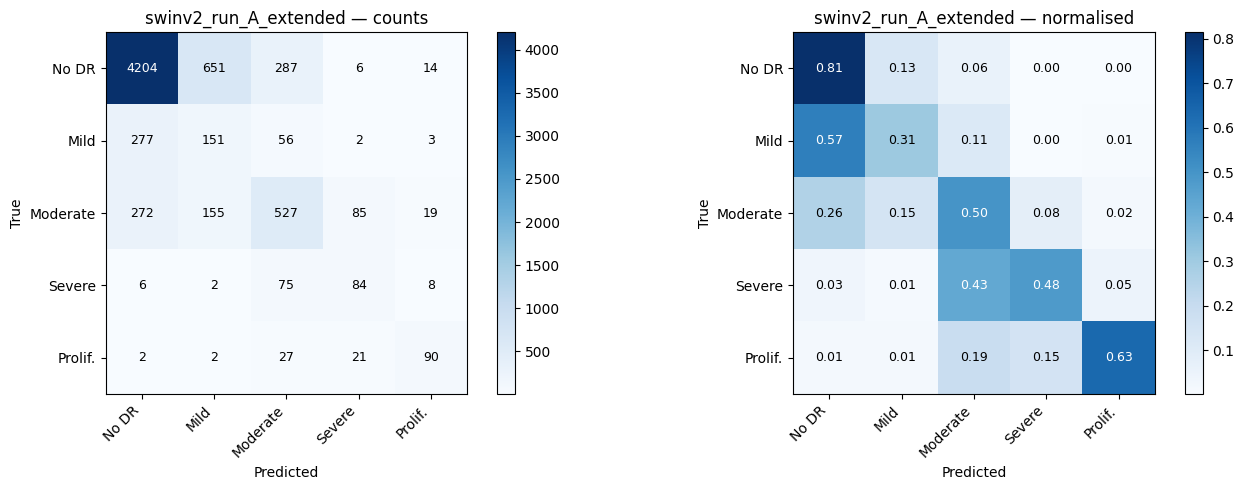

In [33]:
# ── Confusion matrix ──────────────────────────────────────────────────────────
use_p = y_pred_tta if (USE_TTA and "y_pred_tta" in dir()) else y_pred
use_l = y_true_tta if (USE_TTA and "y_true_tta" in dir()) else y_true
suffix = "_tta" if USE_TTA else ""

cm = confusion_matrix(use_l, use_p)
cm_norm = cm.astype(float)/cm.sum(axis=1,keepdims=True)
short = ["No DR","Mild","Moderate","Severe","Prolif."]

fig, axes = plt.subplots(1,2,figsize=(14,5))
for ax, data, title, fmt in zip(axes,
    [cm, cm_norm],
    [f"{EXPERIMENT_NAME} — counts", f"{EXPERIMENT_NAME} — normalised"],
    ["d",".2f"]):
    im = ax.imshow(data, cmap="Blues")
    fig.colorbar(im, ax=ax)
    ax.set(xticks=range(5), yticks=range(5), xticklabels=short, yticklabels=short,
           xlabel="Predicted", ylabel="True", title=title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    for i in range(5):
        for j in range(5):
            ax.text(j,i,format(data[i,j],fmt),ha="center",va="center",fontsize=9,
                    color="white" if data[i,j]>data.max()*0.5 else "black")
fig.tight_layout()
fp = out_dir/f"{EXPERIMENT_NAME}_confusion{suffix}.png"
fig.savefig(fp,dpi=150,bbox_inches="tight"); print(f"Saved → {fp}"); plt.show()

Saved → /scratch/AML_G14_CW/outputs/swinv2_run_A_extended_curves.png


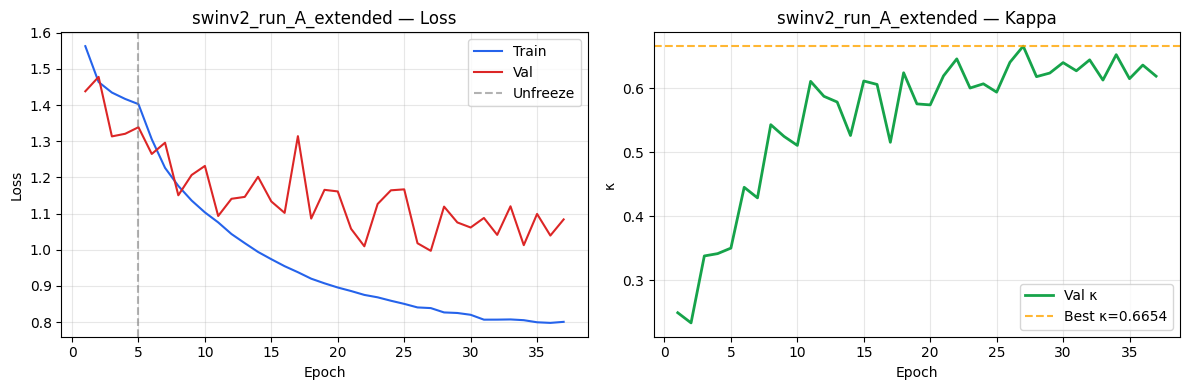

In [34]:
# ── Training curves ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].plot(history["epoch"],history["train_loss"],label="Train",color="#2563EB")
axes[0].plot(history["epoch"],history["val_loss"],  label="Val",  color="#DC2626")
if freeze_epochs>0: axes[0].axvline(x=freeze_epochs,color="gray",linestyle="--",alpha=0.6,label="Unfreeze")
axes[0].set(title=f"{EXPERIMENT_NAME} — Loss",xlabel="Epoch",ylabel="Loss"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(history["epoch"],history["val_kappa"],color="#16A34A",linewidth=2,label="Val κ")
axes[1].axhline(y=best_kappa,color="orange",linestyle="--",alpha=0.8,label=f"Best κ={best_kappa:.4f}")
axes[1].set(title=f"{EXPERIMENT_NAME} — Kappa",xlabel="Epoch",ylabel="κ"); axes[1].legend(); axes[1].grid(alpha=0.3)
fig.tight_layout()
fp = out_dir/f"{EXPERIMENT_NAME}_curves.png"
fig.savefig(fp,dpi=150,bbox_inches="tight"); print(f"Saved → {fp}"); plt.show()

Saved → /scratch/AML_G14_CW/outputs/swinv2_run_A_extended_gradcam.png


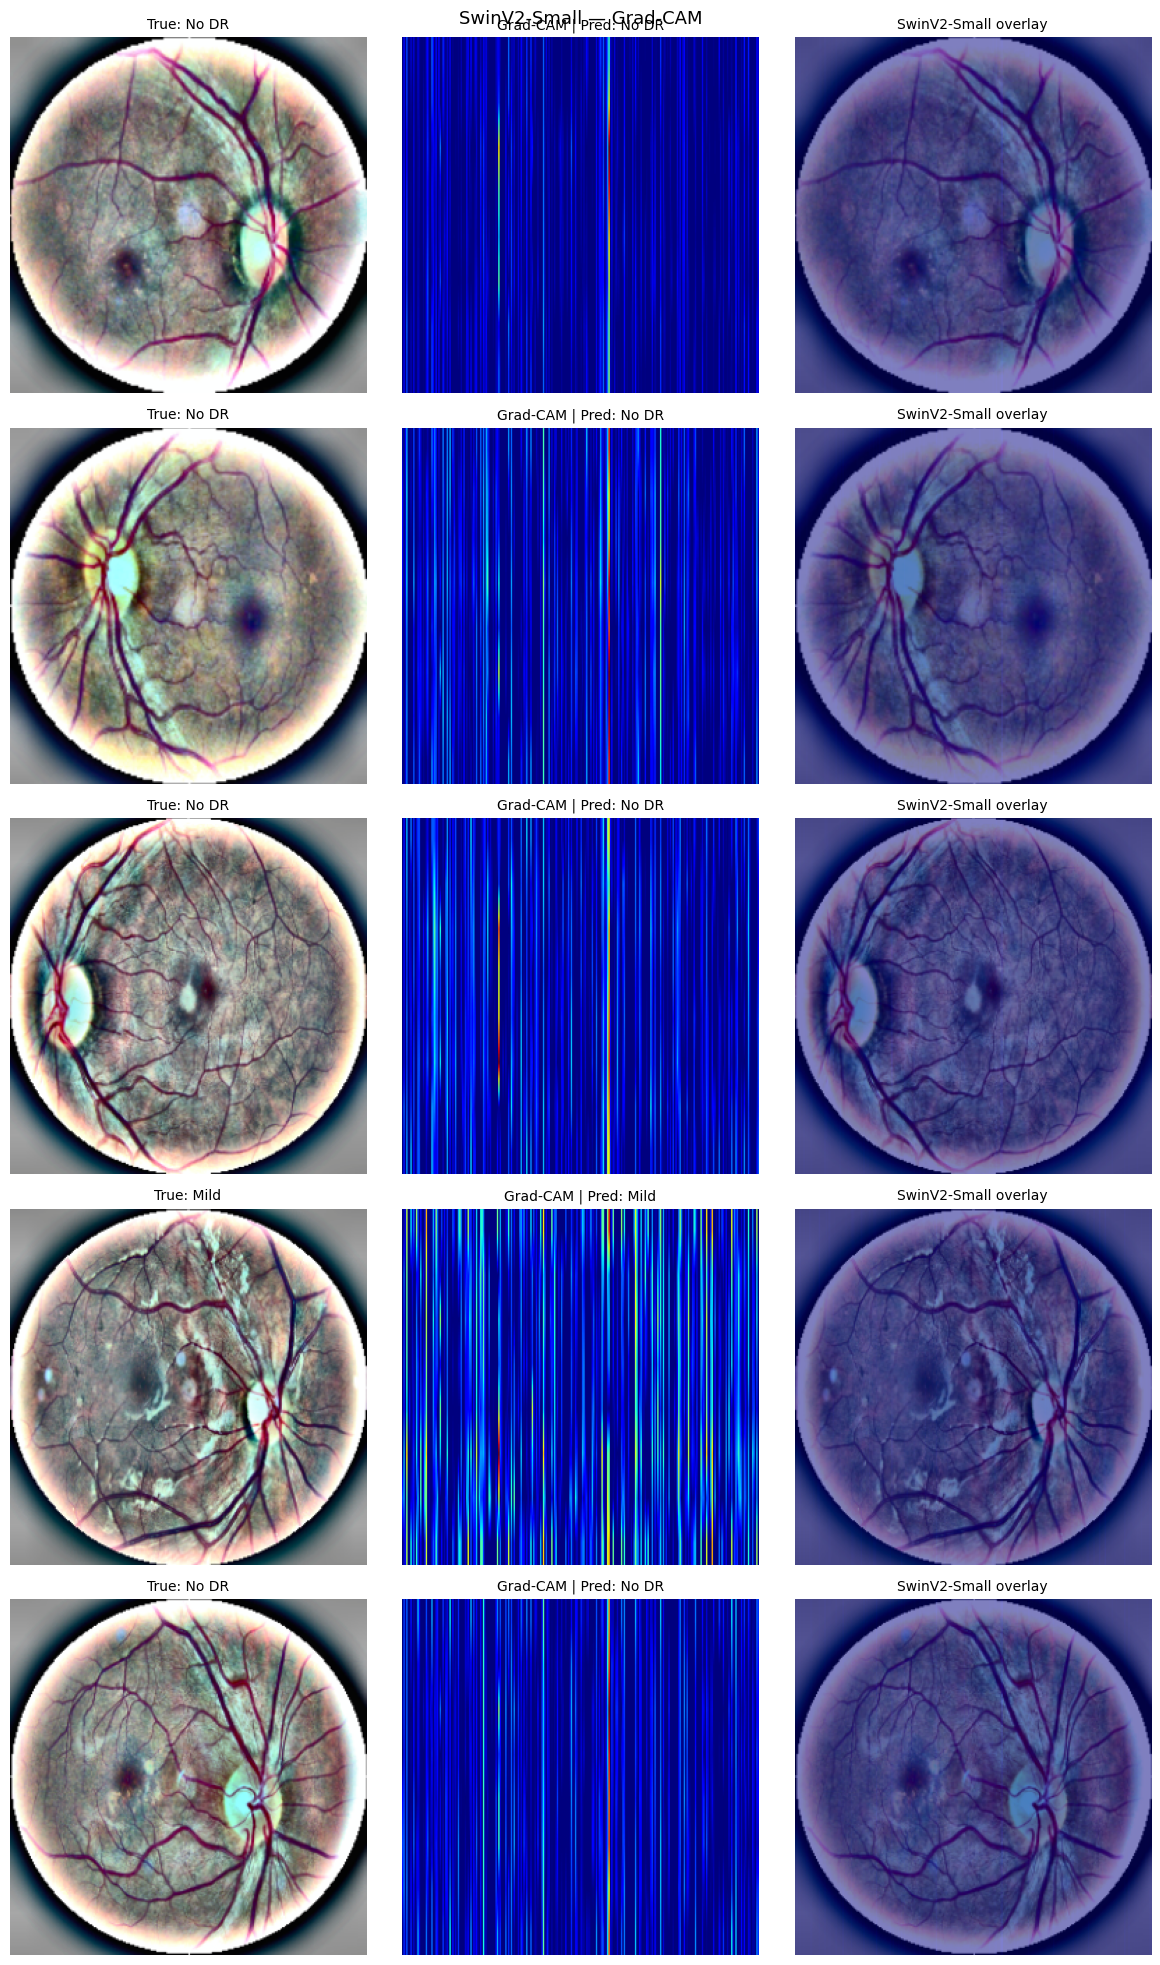

In [35]:
# ── Grad-CAM visualisation ────────────────────────────────────────────────────
class GradCAM:
    """Grad-CAM for SwinV2 (token sequence) and EfficientNet (feature maps)."""
    def __init__(self, mdl, target_layer):
        self.mdl = mdl; self.gradients = None; self.activations = None
        target_layer.register_forward_hook(lambda m,i,o: setattr(self,"activations",o.detach()))
        target_layer.register_full_backward_hook(lambda m,gi,go: setattr(self,"gradients",go[0].detach()))

    def __call__(self, x, class_idx=None):
        self.mdl.eval()
        x = x.unsqueeze(0).to(device)
        logits = self.mdl(x)
        if class_idx is None: class_idx = int(logits.argmax(1).item())
        self.mdl.zero_grad(); logits[0,class_idx].backward()
        grads, acts = self.gradients, self.activations
        if grads.ndim == 3:  # SwinV2 token output
            B,N,C = grads.shape; gs = int(N**0.5)
            grads = grads.reshape(B,gs,gs,C).permute(0,3,1,2)
            acts  = acts.reshape(B,gs,gs,C).permute(0,3,1,2)
        weights = grads.mean(dim=(2,3),keepdim=True)
        cam = F.relu((weights*acts).sum(dim=1).squeeze(0)).cpu().numpy()
        cam = (cam-cam.min())/(cam.max()-cam.min()+1e-8)
        return cv2.resize(cam,(IMAGE_SIZE,IMAGE_SIZE)), class_idx


def show_gradcam(dataset, indices, target_layer, model_name="SwinV2-Small"):
    gc_obj = GradCAM(model, target_layer)
    grade_names = ["No DR","Mild","Moderate","Severe","Proliferative"]
    n = len(indices); fig, axes = plt.subplots(n,3,figsize=(12,4*n))
    if n==1: axes = axes[None]
    mean = np.array(IMAGENET_MEAN); std = np.array(IMAGENET_STD)
    for row, idx in enumerate(indices):
        img_t, true_l = dataset[idx]
        cam, pred_l = gc_obj(img_t)
        orig = np.clip(img_t.permute(1,2,0).numpy()*std+mean,0,1)
        orig_u8 = (orig*255).astype(np.uint8)
        heat = cv2.cvtColor(cv2.applyColorMap((cam*255).astype(np.uint8),cv2.COLORMAP_JET),cv2.COLOR_BGR2RGB)
        overlay = (0.5*heat+0.5*orig_u8).astype(np.uint8)
        for col,(im,title) in enumerate([
            (orig,     f"True: {grade_names[true_l]}"),
            (cam,      f"Grad-CAM | Pred: {grade_names[pred_l]}"),
            (overlay,  f"{model_name} overlay"),
        ]):
            axes[row,col].imshow(im,cmap="jet" if col==1 else None)
            axes[row,col].set_title(title,fontsize=10); axes[row,col].axis("off")
    plt.suptitle(f"{model_name} — Grad-CAM",fontsize=13); plt.tight_layout()
    fp = out_dir/f"{EXPERIMENT_NAME}_gradcam.png"
    plt.savefig(fp,dpi=150,bbox_inches="tight"); print(f"Saved → {fp}"); plt.show()


try:
    target = model.layers[-1].blocks[-1].norm1  # SwinV2 last stage last block
    grade_indices = []
    for g in range(NUM_CLASSES):
        rows = val_df[val_df["level"]==g]
        if len(rows)>0: grade_indices.append(rows.index[0] % len(val_ds))
    show_gradcam(val_ds, grade_indices[:5], target)
except Exception as e:
    print(f"Grad-CAM skipped: {e}")

In [36]:
# ── Experiment summary — commit to GitHub ─────────────────────────────────────
summary = {
    "experiment"    : EXPERIMENT_NAME,
    "architecture"  : ARCHITECTURE,
    "augment"       : AUGMENT_VERSION,
    "imbalance"     : ("focal" if USE_FOCAL_LOSS else "weighted_sampler" if WEIGHTED_SAMPLING else "class_weights"),
    "pretrained"    : PRETRAINED,
    "image_size"    : IMAGE_SIZE,
    "batch_size"    : BATCH_SIZE,
    "lr"            : LR,
    "epochs_run"    : len(history["epoch"]),
    "best_val_kappa": round(best_kappa,5),
    "best_val_f1"   : round(f1_score(y_true,y_pred,average="macro",zero_division=0),5),
    "tta_kappa"     : round(kappa_tta,5) if USE_TTA and "kappa_tta" in dir() else None,
    "history"       : history,
}
sp = out_dir/f"{EXPERIMENT_NAME}_summary.json"
with open(sp,"w") as f: json.dump(summary,f,indent=2)
print("="*60)
print(f"  {EXPERIMENT_NAME}")
print(f"  Kappa     : {best_kappa:.4f}")
print(f"  Macro F1  : {summary['best_val_f1']:.4f}")
if summary["tta_kappa"]: print(f"  TTA Kappa : {summary['tta_kappa']:.4f}")
print(f"  Summary   → {sp}")
print("  Commit this file to GitHub with a descriptive message.")

  swinv2_run_A_extended
  Kappa     : 0.6654
  Macro F1  : 0.5252
  TTA Kappa : 0.6813
  Summary   → /scratch/AML_G14_CW/outputs/swinv2_run_A_extended_summary.json
  Commit this file to GitHub with a descriptive message.
